Iteration 1: Best Fitness = 0.08035
Iteration 2: Best Fitness = 0.06368
Iteration 3: Best Fitness = 0.06368
Iteration 4: Best Fitness = 0.06368
Iteration 5: Best Fitness = 0.06368
Iteration 6: Best Fitness = 0.06368
Iteration 7: Best Fitness = 0.06368
Iteration 8: Best Fitness = 0.06368
Iteration 9: Best Fitness = 0.05912
Iteration 10: Best Fitness = 0.05912
Iteration 11: Best Fitness = 0.05912
Iteration 12: Best Fitness = 0.05912
Iteration 13: Best Fitness = 0.05912
Iteration 14: Best Fitness = 0.05912
Iteration 15: Best Fitness = 0.05912
Iteration 16: Best Fitness = 0.05912
Iteration 17: Best Fitness = 0.05912
Iteration 18: Best Fitness = 0.05912
Iteration 19: Best Fitness = 0.05912
Iteration 20: Best Fitness = 0.05912
Iteration 21: Best Fitness = 0.05912
Iteration 22: Best Fitness = 0.05912
Iteration 23: Best Fitness = 0.05912
Iteration 24: Best Fitness = 0.05912
Iteration 25: Best Fitness = 0.05912
Iteration 26: Best Fitness = 0.05912
Iteration 27: Best Fitness = 0.05912
Iteration 

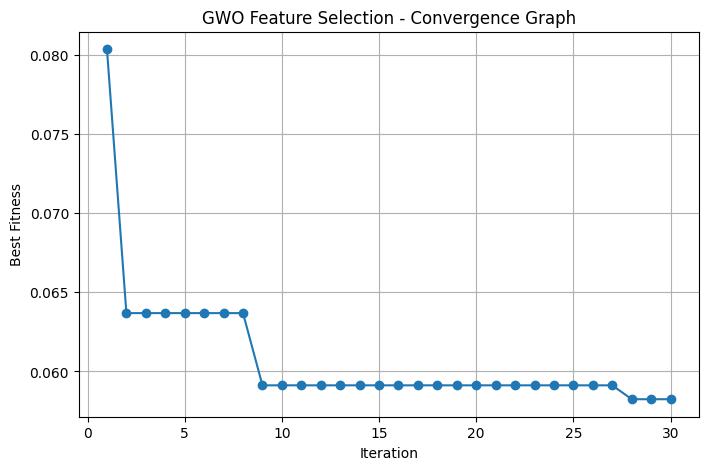

In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


# -----------------------------------------
# 1. Load and prepare the dataset
# -----------------------------------------

data = load_breast_cancer()

X = data.data
y = data.target
feature_names = data.feature_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

total_features = X_train.shape[1]


# -----------------------------------------
# 2. GWO parameters
# -----------------------------------------

population_size = 20
max_iterations = 30
local_directions = 5

alpha_weight = 0.9


# -----------------------------------------
# 3. Convert continuous position to binary
# -----------------------------------------

def binary_conversion(position):

    probability = 1 / (1 + np.exp(-np.clip(position, -50, 50)))

    return (np.random.rand(len(position)) < probability).astype(int)


# -----------------------------------------
# 4. Fitness function
# -----------------------------------------

def fitness(position):

    selected = np.where(position == 1)[0]

    if len(selected) == 0:
        return 1.0

    model = KNeighborsClassifier(n_neighbors=5)

    model.fit(X_train[:, selected], y_train)

    predictions = model.predict(X_test[:, selected])

    error_rate = 1 - accuracy_score(y_test, predictions)

    feature_ratio = len(selected) / total_features

    score = (
        alpha_weight * error_rate
        + (1 - alpha_weight) * feature_ratio
    )

    return score


# -----------------------------------------
# 5. Random local search
# -----------------------------------------

def random_local_search(position, radius):

    current_binary = binary_conversion(position)
    best_position = position.copy()
    best_fitness = fitness(current_binary)

    for _ in range(local_directions):

        candidate = position.copy()

        # Randomly select dimensions
        dimensions = np.random.choice(
            total_features,
            size=min(3, total_features),
            replace=False
        )

        # Perturb selected dimensions
        for d in dimensions:

            candidate[d] += np.random.uniform(-radius, radius)

        candidate = np.clip(candidate, 0, 1)

        binary_candidate = binary_conversion(candidate)
        candidate_fitness = fitness(binary_candidate)

        if candidate_fitness < best_fitness:

            best_fitness = candidate_fitness
            best_position = candidate.copy()

    return best_position


# -----------------------------------------
# 6. Grey Wolf Optimization
# -----------------------------------------

wolves = np.random.rand(population_size, total_features)

alpha_pos = np.zeros(total_features)
beta_pos = np.zeros(total_features)
delta_pos = np.zeros(total_features)

alpha_score = float("inf")
beta_score = float("inf")
delta_score = float("inf")

convergence = []


for iteration in range(max_iterations):

    # Evaluate all wolves
    for i in range(population_size):

        binary_position = binary_conversion(wolves[i])
        score = fitness(binary_position)

        if score < alpha_score:

            delta_score = beta_score
            delta_pos = beta_pos.copy()

            beta_score = alpha_score
            beta_pos = alpha_pos.copy()

            alpha_score = score
            alpha_pos = wolves[i].copy()

        elif score < beta_score:

            delta_score = beta_score
            delta_pos = beta_pos.copy()

            beta_score = score
            beta_pos = wolves[i].copy()

        elif score < delta_score:

            delta_score = score
            delta_pos = wolves[i].copy()

    # Control parameters
    a = 2 - iteration * (2 / max_iterations)

    # Decreasing local search radius
    radius = 1 / ((iteration + 1) ** 2)

    for i in range(population_size):

        current = wolves[i].copy()

        # ---------------------------------
        # Global GWO position update
        # ---------------------------------

        r1 = np.random.rand(total_features)
        r2 = np.random.rand(total_features)

        A1 = 2 * a * r1 - a
        C1 = 2 * r2

        D_alpha = abs(C1 * alpha_pos - current)
        X1 = alpha_pos - A1 * D_alpha

        r1 = np.random.rand(total_features)
        r2 = np.random.rand(total_features)

        A2 = 2 * a * r1 - a
        C2 = 2 * r2

        D_beta = abs(C2 * beta_pos - current)
        X2 = beta_pos - A2 * D_beta

        r1 = np.random.rand(total_features)
        r2 = np.random.rand(total_features)

        A3 = 2 * a * r1 - a
        C3 = 2 * r2

        D_delta = abs(C3 * delta_pos - current)
        X3 = delta_pos - A3 * D_delta

        global_update = (X1 + X2 + X3) / 3

        global_update = np.clip(global_update, 0, 1)

        # ---------------------------------
        # Random local search
        # ---------------------------------

        local_position = random_local_search(current, radius)

        C = 2 * np.random.rand(total_features)

        local_update = abs(C * local_position - current)

        # ---------------------------------
        # First-element dominance
        # ---------------------------------

        combinations = [
            global_update,

            global_update[0] + local_update,

            0.5 * global_update[0] + 0.5 * local_update,

            0.6 * global_update[0] + 0.4 * local_update,

            0.7 * global_update[0] + 0.3 * local_update,

            0.8 * global_update[0] + 0.2 * local_update
        ]

        best_candidate = current.copy()
        best_candidate_score = float("inf")

        for candidate in combinations:

            candidate = np.clip(candidate, 0, 1)

            binary_candidate = binary_conversion(candidate)

            candidate_score = fitness(binary_candidate)

            if candidate_score < best_candidate_score:

                best_candidate_score = candidate_score
                best_candidate = candidate.copy()

        # Update wolf position
        wolves[i] = best_candidate

    convergence.append(alpha_score)

    print(
        f"Iteration {iteration + 1}: "
        f"Best Fitness = {alpha_score:.5f}"
    )


# -----------------------------------------
# 7. Display selected features
# -----------------------------------------

best_features = binary_conversion(alpha_pos)

selected_indices = np.where(best_features == 1)[0]

print("\n========== FINAL RESULT ==========")

print("Total Features:", total_features)

print("Selected Features:", len(selected_indices))

print("\nSelected Feature Names:")

for index in selected_indices:
    print("-", feature_names[index])


# -----------------------------------------
# 8. Calculate final accuracy
# -----------------------------------------

if len(selected_indices) > 0:

    final_model = KNeighborsClassifier(n_neighbors=5)

    final_model.fit(
        X_train[:, selected_indices],
        y_train
    )

    final_predictions = final_model.predict(
        X_test[:, selected_indices]
    )

    final_accuracy = accuracy_score(
        y_test,
        final_predictions
    )

    print("\nClassification Accuracy:",
          round(final_accuracy * 100, 2), "%")


# -----------------------------------------
# 9. Plot convergence graph
# -----------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, max_iterations + 1),
    convergence,
    marker='o'
)

plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("GWO Feature Selection - Convergence Graph")

plt.grid(True)
plt.show()
